# Ảnh hưởng của chuẩn hóa đặc trưng đến Gradient Descent trên dữ liệu giá nhà (mục 5.3.1)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
DATA = Path('..') / 'data'   # thư mục data/

df = pd.read_csv(DATA / "house_prices.csv")
X = df[["area", "bedrooms", "distance"]].values   # diện tích, số phòng ngủ, khoảng cách
y = df["price"].values                             # giá nhà (triệu VND)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def add_ones(X):
    """Thêm cột 1 vào trước X (vector mở rộng)."""
    return np.column_stack([np.ones(len(X)), X])

def cost(w, Xb, y):
    """Hàm mất mát L(w) = 1/(2N) ||Xb w - y||^2."""
    return .5 / len(y) * np.sum((Xb @ w - y)**2)

def batch_gd(Xb, y, eta, n_iters):
    """Batch GD từ w = 0, trả về L(w) sau mỗi vòng lặp."""
    w = np.zeros(Xb.shape[1])
    losses = [cost(w, Xb, y)]
    for _ in range(n_iters):
        w = w - eta * Xb.T @ (Xb @ w - y) / len(y)
        losses.append(cost(w, Xb, y))
    return losses

mu, std = X_train.mean(axis=0), X_train.std(axis=0)   # trung bình μ và độ lệch chuẩn σ
Xb_raw = add_ones(X_train)                     # dữ liệu gốc
Xb_scaled = add_ones((X_train - mu) / std)     # dữ liệu đã chuẩn hóa
w_ols = np.linalg.pinv(Xb_raw.T @ Xb_raw) @ Xb_raw.T @ y_train
L_min = cost(w_ols, Xb_raw, y_train)           # giá trị nhỏ nhất của L

Vẽ hình và lưu ảnh.

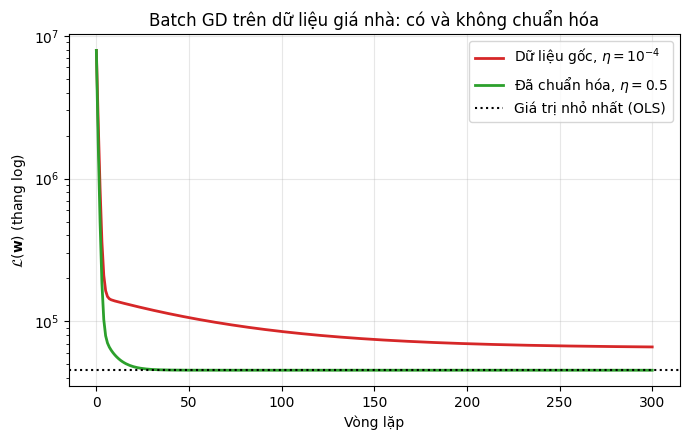

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(batch_gd(Xb_raw, y_train, 1e-4, 300), color="#D62728", lw=2,
        label=r"Dữ liệu gốc, $\eta = 10^{-4}$")
ax.plot(batch_gd(Xb_scaled, y_train, 0.5, 300), color="#2CA02C", lw=2,
        label=r"Đã chuẩn hóa, $\eta = 0.5$")
ax.axhline(L_min, color="black", ls=":", label="Giá trị nhỏ nhất (OLS)")
ax.set_yscale("log")
ax.set_xlabel("Vòng lặp"); ax.set_ylabel(r"$\mathcal{L}(\mathbf{w})$ (thang log)")
ax.set_title("Batch GD trên dữ liệu giá nhà: có và không chuẩn hóa")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "feature_scaling.png", dpi=150)